# KQC CrossingTwoface — flip-chip line crossings (top-chip bridges) and a crosstalk pair (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/crossing_twoface.py` (`CrossingTwoface`, default parameters, chip name "CTest"),
© IQM Finland Oy, GPL-3.0 (`other-libs/KQCircuits-main/.../kqcircuits/chips/crossing_twoface.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *CrossingTwoface*).

The flip-chip version of `AirbridgeCrossings`: PL-1 (NW → SW) and PL-2 (NE → SE) run straight down at x = 4300 and
5700 µm on the bottom chip (face `1t1`), widened to the capped CPW (a = b = 10 µm) under the top chip. PL-3 (WN → WS)
weaves across PL-1 six times; at each crossing it jumps to the top chip (face `2b1`) through a `FlipChipConnectorRf`
400 µm before PL-1 and comes back 400 µm after it, so the two lines cross on different faces. PL-4 (EN → ES) weaves
300 µm from PL-2 on the bottom chip without crossing (the crosstalk reference).

**Kept exactly (same KQC paths and parameters):** the SMA8 launcher assignment
{1: PL-1-IN, 2: PL-2-IN, 3: PL-4-IN, 4: PL-4-OUT, 5: PL-2-OUT, 6: PL-1-OUT, 7: PL-3-OUT, 8: PL-3-IN}; the four lines
as Designer routes with KQC's nodes: the 2r jogs out of the launcher corners, the capped-CPW tapers at the top-chip
edge (KQC `Node(..., a=a_capped, b=b_capped)` → route waypoints with `a`, `b`), the weave of PL-3 and PL-4
(`crossings = 3`, step = 4400 / 2.5 / 2 = 880 µm, wiggle = 400 / 2 + 250 µm) and PL-3's face changes as waypoints
with `face_id` (KQC `Node(..., face_id=...)`; KQC's `WaveguideComposite` inserts the `FlipChipConnectorRf` there, as
in the source). Results 1 XORs the chip with a stand-alone KQC build.

**Simplified:** nothing. `meander_face = "single"` (default): PL-4 stays on the bottom chip.

**Faces in DRC and LOM:** the DRC `crossing` rule is face-aware (each segment takes the face of the last `face_id`
waypoint), so PL-3's top-chip spans over PL-1 are no crossing error. The LOM is face-agnostic: each line is one
conductor between two 50 Ω launchers.

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in); same assignment |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | the same whole-area coverage with the PDK squares: chip `cheese: "chip"` puts 5 µm squares with 20 µm gaps (instead of KQC's 5 µm on a 10 µm step) over the whole die, at least 4 µm from the 3/0 keep-outs and clear of the frame markers and the device ID |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (checked in Design 5, no shift) |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its SMA8 launchers, the launchers and the pad rule, the two straight lines under the top chip (what the crossings go over), the routing of the two weaving lines (PL-3 with its six flip-chip crossings, PL-4 the crosstalk reference), and then the whole chip (the centring and the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `crossing_twoface.v1.ipynb`; both save the same `crossing_twoface.json`.

This test chip has no circuit to simulate (through lines only): the LOM and Simulate steps say in one sentence why
not, and the Results step is the comparison with KQC's own build (the XOR); Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/crossing_twoface/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/crossing_twoface")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way it is laid out by hand: the die and its launchers, the pad check, the lines the test is
about, the lines that cross them, and then the whole chip. A process test chip has no qubits, readout or coupling, so
those segments are not here. The test structures are the crossings themselves, and they are part of PL-3's route (a
face change before and after PL-1, where KQC's `WaveguideComposite` inserts a `FlipChipConnectorRf`), so the chip has
no instances at all: segment 3 draws the two straight lines that get crossed, segment 4 the two weaving lines. The
routes keep the v1's order. The PDK cheese (`cheese: "chip"`, ≈ 0.14 M holes over the whole die) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 holder's eight launchers (KQC's assignment) |
| 2 | the launchers and the pad rule (they come with the die): nothing added, the check and a zoom |
| 3 | the test structures' fixed half: PL-1 and PL-2, straight down under the top chip, widened to the capped CPW there |
| 4 | the routing: PL-3 weaving across PL-1 with a face change before and after each crossing (six flip-chip crossings), PL-4 weaving beside PL-2 on the bottom chip (the crosstalk reference) |
| 5 | the whole chip: the centring check and the save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID) and KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn). `cheese: "chip"` asks for the PDK cheese over the whole die: KQC's source grids its whole ground plane (`with_grid=True`, 5 µm holes on a 10 µm step), and the rebuild keeps that coverage with the PDK squares (5 µm with 20 µm gaps, at least 4 µm from the 3/0 keep-outs). The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

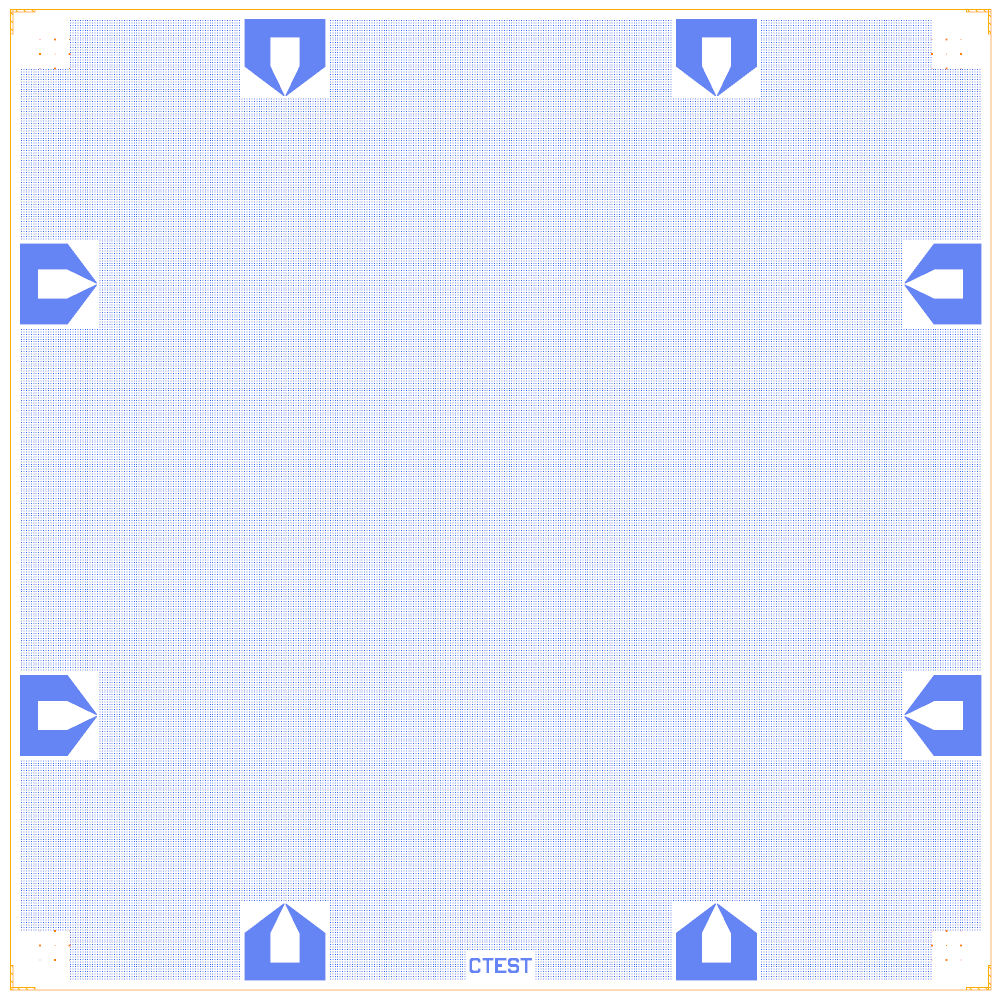

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/crossing_twoface/1_die.png')

In [5]:
pads = {1: "PL-1-IN", 2: "PL-2-IN", 3: "PL-4-IN", 4: "PL-4-OUT", 5: "PL-2-OUT", 6: "PL-1-OUT", 7: "PL-3-OUT", 8: "PL-3-IN"}
d = Designer("crossing_twoface", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "assign": pads},
             chip={"name_chip": "CTest", "cheese": "chip"}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-IN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-OUT | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

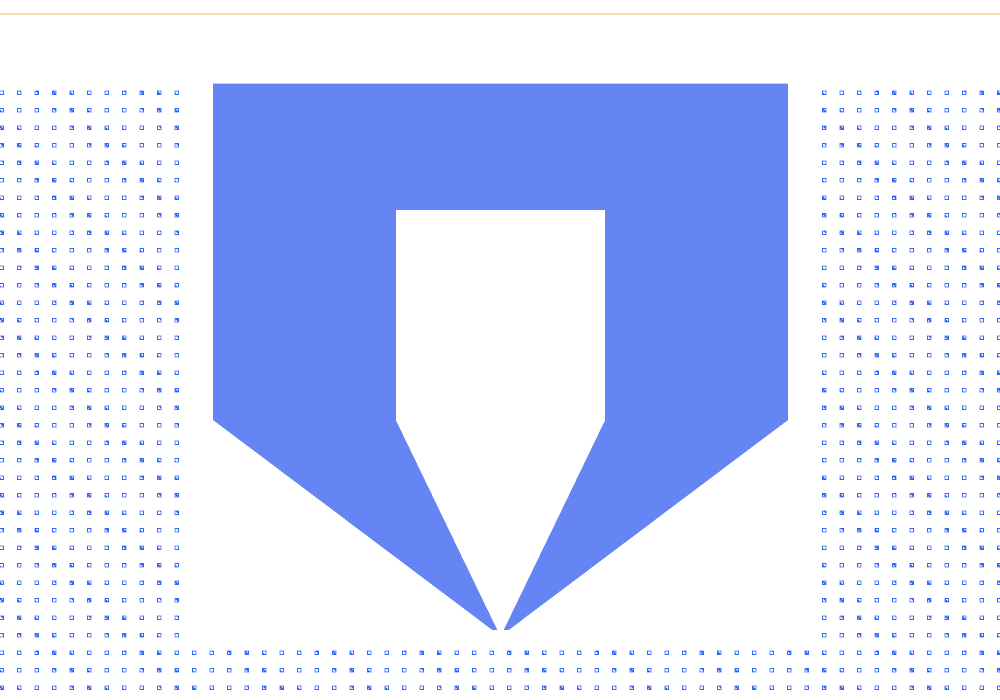

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.PL-1-IN")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Test structures: the two straight lines the crossings go over

PL-1 and PL-2 go out of their launcher corners by 2r, across to x = 4300 / 5700 µm, widen to the capped CPW (a = b = 10 µm) under the top chip and come back the same way. The face
changes of Design 4 make PL-3 cross these lines on the top chip, so PL-1 is the line under test and PL-2 its
uncrossed twin (KQC defaults: `a`, `b` = 10, 6 µm on the chip, `a_capped`, `b_capped` = 10, 10 µm under the top chip,
the top chip's box 1500 … 8500 µm).

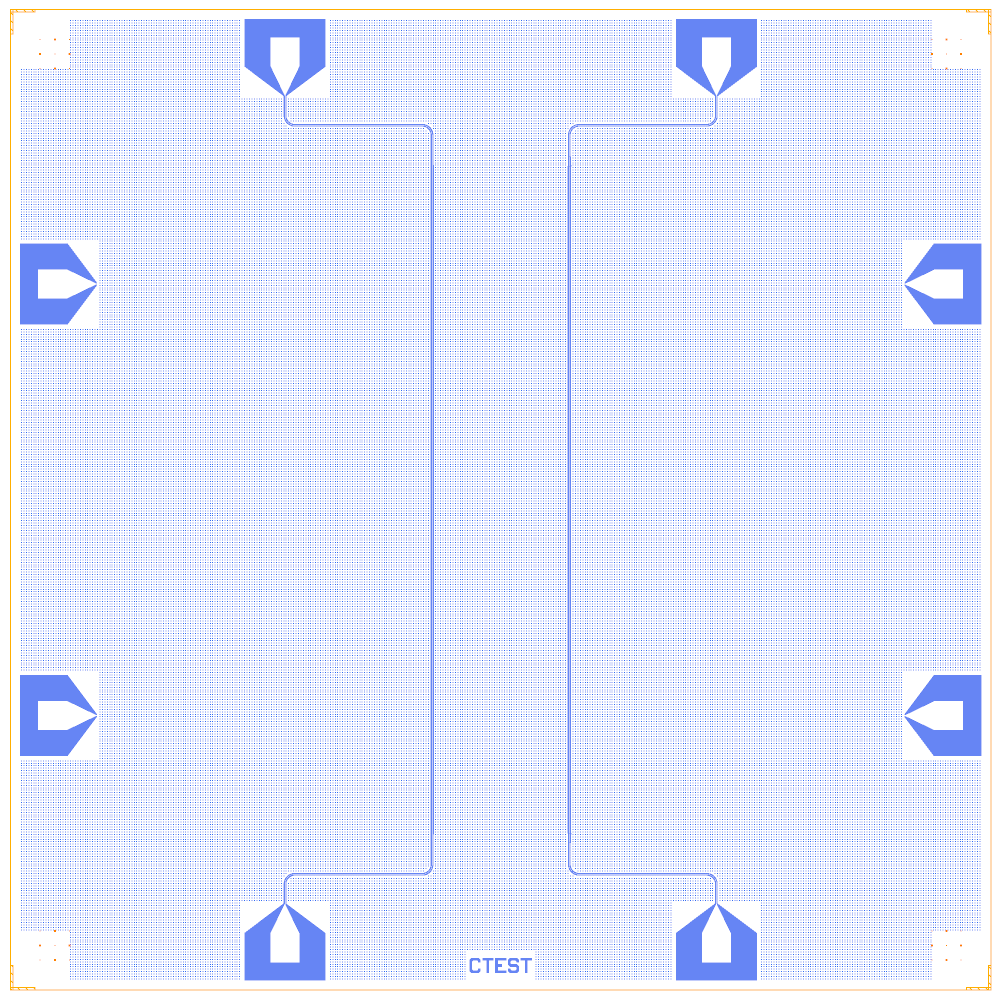

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `PL1`, `PL2`.

WindowsPath('build/snapshots/crossing_twoface/s3_straight.png')

In [7]:
W = d.waypoint
a, b, a_c, b_c, r = 10, 6, 10, 10, 100          # chip CPW, capped CPW (a_capped, b_capped), turn radius
top = (1500, 1500, 8500, 8500)                    # top-chip (face 1) box
crossings, crossing_length, cross_talk_distance = 3, 400, 300   # KQC defaults
left_x, right_x = 5000 - 700, 5000 + 700
P = {n: port_xy(d, f"chip.{n}") for n in pads.values()}
with d.batch():
    # PL-1 / PL-2: out of the launcher corner by 2r, across to x, capped under the top chip, back the same way
    for name, x in (("PL1", left_x), ("PL2", right_x)):
        k = name[-1]
        (ix, iy), (ox, oy) = P[f"PL-{k}-IN"], P[f"PL-{k}-OUT"]
        y_in, y_out = iy - r - 2 * r, oy + r + 2 * r          # KQC: port corner ∓ 2r
        d.route(name, f"chip.PL-{k}-IN", f"chip.PL-{k}-OUT",
                nodes=[(ix, y_in), (x, y_in), W((x, top[3]), a=a_c, b=b_c), W((x, top[1] + 100), a=a, b=b),
                       (x, y_out), (ox, y_out)])
layout_step(d, STEPS / "s3_straight.png", **CHIP)

## Design 4 · Routing: PL-3 with its flip-chip crossings, and PL-4

PL-3 weaves across PL-1 six times; at each crossing a waypoint with `face_id="2b1"` 400 µm before PL-1 and one with `face_id="1t1"` after it make KQC's `WaveguideComposite` insert a `FlipChipConnectorRf` there, so the two lines cross on different faces. PL-4 weaves 300 µm from PL-2 on the bottom chip only. PL-4 uses PL-3's weave
step, so both are in this cell. The first picture is the whole chip, the second zooms on PL-4's first wiggles beside
PL-2 (the crossings of PL-3 and one connector are in Fab 2).

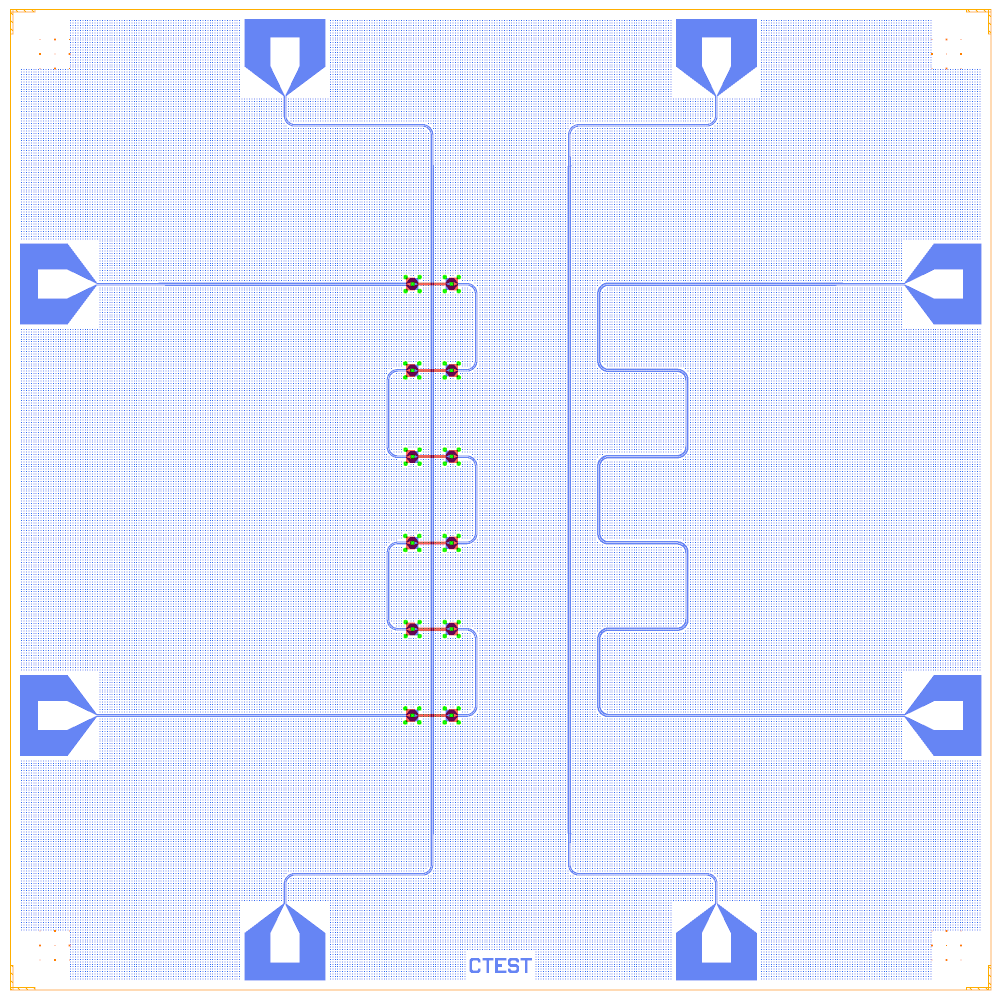

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 4 routes · 0 declared couplings. **This step added** 2 route(s) `PL3`, `PL4`.

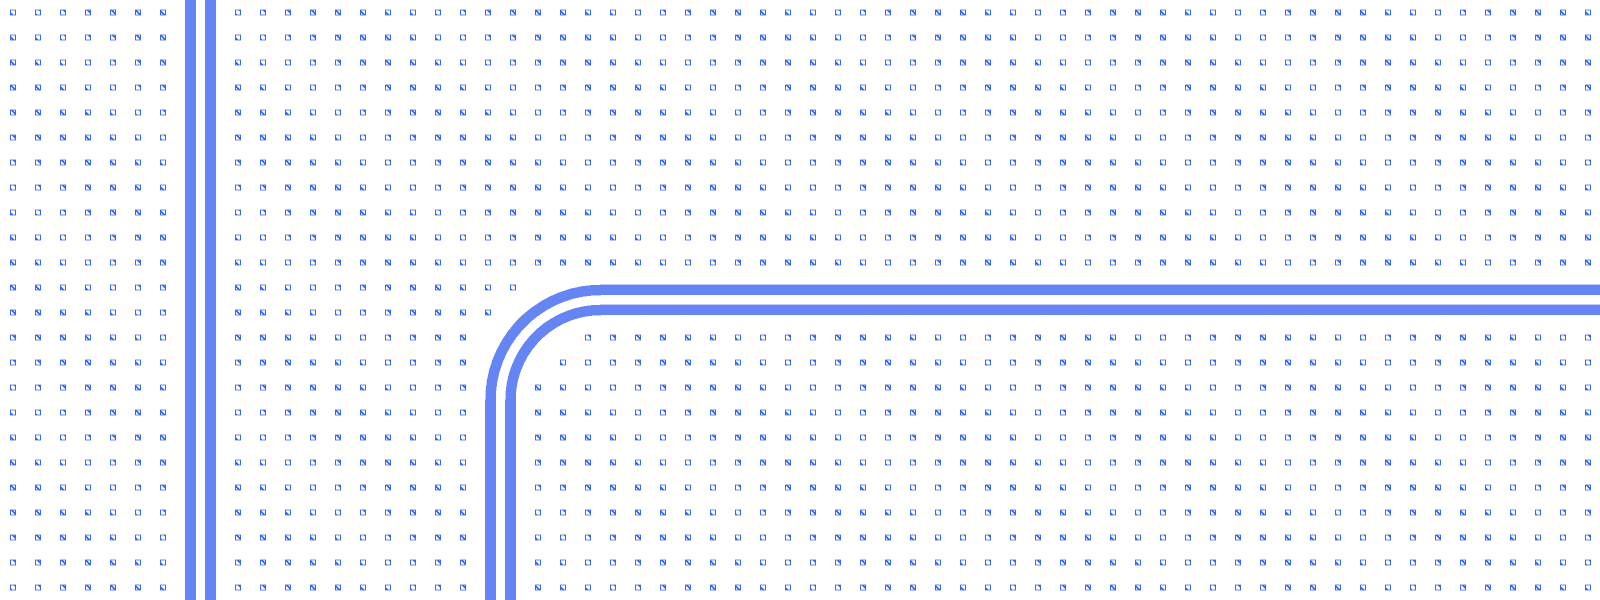

{'PL1': 11068.32, 'PL2': 11068.32, 'PL3': 13870.8, 'PL4': 13810.8}


In [8]:
with d.batch():
    # PL-3: weaves across PL-1, each crossing on the top chip (face 2b1) between x ∓ crossing_length / 2
    (ix, iy), (ox, oy) = P["PL-3-IN"], P["PL-3-OUT"]
    step = (iy - oy) / (crossings - 0.5) / 2
    wiggle = crossing_length / 2 + 250
    x1, x2 = left_x - crossing_length / 2, left_x + crossing_length / 2
    nodes, y = [W((top[0], iy), a=a_c, b=b_c)], iy
    for _ in range(crossings):
        nodes += [(left_x - wiggle, y), W((x1, y), face_id="2b1"), W((x2, y), face_id="1t1"), (left_x + wiggle, y)]
        y -= step
        nodes += [(left_x + wiggle, y), W((x2, y), face_id="2b1"), W((x1, y), face_id="1t1"), (left_x - wiggle, y)]
        y -= step
    d.route("PL3", "chip.PL-3-IN", "chip.PL-3-OUT", nodes=nodes + [W((top[0] + 100, oy), a=a, b=b)])
    # PL-4: the same weave next to PL-2, bottom chip only
    (ix, iy), (ox, oy) = P["PL-4-IN"], P["PL-4-OUT"]
    xr = right_x + cross_talk_distance + wiggle
    nodes, y = [W((top[2], iy), a=a_c, b=b_c)], iy
    for _ in range(crossings):
        nodes += [(xr + wiggle, y), (xr - wiggle, y)]
        y -= step
        nodes += [(xr - wiggle, y), (xr + wiggle, y)]
        y -= step
    d.route("PL4", "chip.PL-4-IN", "chip.PL-4-OUT", nodes=nodes + [W((top[2] - 100, oy), a=a, b=b)])
layout_step(d, STEPS / "4_routes.png", **CHIP)
snap(d, STEPS / "s4_pl4.png", box=(5500, 6900, 7100, 7500), size=(1600, 600), width=560)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

## Design 5 · The whole chip: centring, save

No sim groups: through lines only (the v1 rebuild has none; Simulate says what one would take). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved with `save_design`, which compares it with the file it replaces (the
previous run's): the routes are added in the v1's order, so it should say *same design*.

In [9]:
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "crossing_twoface.json")
display(Markdown(same))
print(d, "→", DESIGN)

centring shift (µm):

 (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/crossing_twoface.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer crossing_twoface: 0 instances, 4 routes, live=False> → examples\designs\kqc\test_chips\crossing_twoface.json


# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean: no errors, no warnings and no PDK design warning. PL-3's top-chip spans over PL-1 raise no `crossing` error: the rule is face-aware (each segment takes the face of the last `face_id` waypoint). `pdk_report` gives the PDK cheese ("PDK cheese over the whole die (drawn in the build)"), the content centred (0, 0) and no junctions. The LOM is face-agnostic: each line is one conductor between two 50 Ω launchers.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: nothing to simulate

None: no junctions or resonators (four 50 Ω through lines). The chip measures the transmission through the flip-chip crossings and the PL-1 ↔ PL-3 and PL-2 ↔ PL-4 crosstalk: a driven S-parameter problem.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups, so the export below writes no FEM job and the switches at the top change nothing here.
What the chip measures, the transmission through the flip-chip crossings and the crosstalk between neighbouring lines, is a driven S-parameter problem: `sim_tools` exports `hfss_driven` jobs, but for a sim group, and adding
one would change the design file (a new revision of the chip, not this rebuild).

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: the layout against the source

The chip has no simulated quantity to hold against a model, so its *compare* step is the XOR with KQC's own build of
the same chip.

## Results 1 · XOR with KQC

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers with their lines' first legs (80 µm deeper here). A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.crossing_twoface import CrossingTwoface as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

**From the v1 run:** the XOR (1.7 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer alone 1 × 10⁸ µm²), the ground grid and its avoidance, KQC's frames on both faces (dicing, EBL and airbridge-marker layers; the top chip's base etch 4.6 × 10⁶ µm²) and the launchers' 80 µm shift (waveguide path 1.4 × 10⁵ µm²). The flip-chip connectors' bumps and UBM agree exactly (XOR 0).

## Results 2 · Feedback: none

There is no target to iterate towards: the lines follow KQC's paths and parameters, and a variant (another crossing count or crossing length) is a
new layout, checked again by the DRC and the XOR above.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `crossing_twoface.json` (saved in Design 5) is the whole design: `qcc build
examples/designs/kqc/test_chips/crossing_twoface.json` rebuilds `build/crossing_twoface.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the top chip's etch on 800/0, the flip-chip connectors' bumps on 801/0 and UBM on 802/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: the PDK cheese drawn over the whole die in the build (`cheese: "chip"`) stands, and no PDK band is added. In the v1 run: 1/0 883 620 polygons, 3/0 862 309, the top chip's etch 6 (800/0) and the flip-chip connectors' 60 bumps (801/0) and 60 UBM pads (802/0); cheese source `build`, 883 605 holes (the bottom chip) (KQC's grid then; the PDK cheese now drawn in the build: 137 890 holes in a probe). Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/crossing_twoface.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and one PL-3 crossing (both faces' layers) in the **fab view** (the mask from Fab 1: 1/0
and 3/0 with the cheese holes). The PDK cheese gives the ground a light, even texture at full-chip scale; the chip boundary 100/0
is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "crossing_twoface.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "crossing_twoface_crossing.png", box=(3800, 6950, 4800, 7450), size=(1600, 800), width=560)
show_snapshot(d, OUT / "crossing_twoface_connector.png", box=(4000, 7100, 4200, 7300), width=360)
show_snapshot(d, OUT / "crossing_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "crossing_twoface_fab.oas", OUT / "crossing_twoface_fab.png", box=(3800, 6950, 4800, 7450), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; the whole-area cheese coverage (with the PDK squares instead of KQC's grid) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`) with the lines' first legs; sapphire; the PDK cheese on the bottom chip instead of KQC's grid |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | built in five segments (die and launchers, the launcher check, the two straight lines, the two weaving lines with PL-3's flip-chip crossings, the whole chip); the saved JSON is the v1 notebook's |
| feedback | none: through lines, no simulated quantity; the XOR with KQC is the compare step (Results 1) |
| open | a driven S-parameter job of one crossing would need a sim group (a new design revision), and a two-face export (the PDK `face_stack` has one face) |